<a href="https://colab.research.google.com/github/FABYG6/DL_Redes_Neuronales_Basicas/blob/main/Implementaci%C3%B3n_GAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Preparación del conjunto de datos
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Implementación de la DCGAN
# Arquitectura del Generador
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(100, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.main(x)


In [12]:
# Arquitectura del Discriminador
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2),

            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)


### Descarga de Datos y Creación del DataLoader (CIFAR-10)
Descargamos el dataset CIFAR-10 y lo preparamos utilizando las transformaciones especificadas en la primera celda.

In [13]:
import torch
from torch.utils.data import DataLoader

# Definir el tamaño del lote antes de usarlo
batch_size = 128

# Descarga del dataset de entrenamiento CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Creación del DataLoader
dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

print(f"DataLoader creado con éxito. Total de lotes (batches): {len(dataloader)}")

DataLoader creado con éxito. Total de lotes (batches): 391


In [14]:
# Configurar dispositivo (GPU o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# Hiperparámetros de entrenamiento
batch_size = 128
epochs = 5      # Reducido a 5 para una prueba rápida, puedes subirlo a 50
lr = 0.0002
beta1 = 0.5
nz = 100

# Instanciar modelos y enviarlos al dispositivo
netG = Generator().to(device)
netD = Discriminator().to(device)

# Inicialización de pesos recomendada para DCGAN
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG.apply(weights_init)
netD.apply(weights_init)

# Función de pérdida y optimizadores
criterion = nn.BCELoss()

optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

# Ruido fijo para evaluar el progreso visual del generador más tarde
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Etiquetas reales y falsas
real_label = 1.
fake_label = 0.

G_losses = []
D_losses = []

print("Iniciando el entrenamiento...")
for epoch in range(epochs):
    for i, data in enumerate(dataloader):

        ############################
        # 1. Actualizar Discriminador: maximizar log(D(x)) + log(1 - D(G(z)))
        ###########################
        netD.zero_grad()

        # Entrenar con datos reales
        real_cpu = data[0].to(device)
        b_size = real_cpu.size(0)
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)

        output = netD(real_cpu).view(-1)
        errD_real = criterion(output, label)
        errD_real.backward()
        D_x = output.mean().item()

        # Entrenar con datos falsos
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label.fill_(fake_label)

        output = netD(fake.detach()).view(-1)
        errD_fake = criterion(output, label)
        errD_fake.backward()
        D_G_z1 = output.mean().item()

        errD = errD_real + errD_fake
        optimizerD.step()

        ############################
        # 2. Actualizar Generador: maximizar log(D(G(z)))
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # Las etiquetas para el generador son reales

        output = netD(fake).view(-1)
        errG = criterion(output, label)
        errG.backward()
        D_G_z2 = output.mean().item()

        optimizerG.step()

        # Guardar pérdidas para graficar
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        if i % 50 == 0:
            print(f"[{epoch}/{epochs}][{i}/{len(dataloader)}] Loss_D: {errD.item():.4f} Loss_G: {errG.item():.4f}")

Usando dispositivo: cpu
Iniciando el entrenamiento...
[0/5][0/391] Loss_D: 1.6295 Loss_G: 4.3761
[0/5][50/391] Loss_D: 2.3044 Loss_G: 25.0787
[0/5][100/391] Loss_D: 0.1984 Loss_G: 4.4554
[0/5][150/391] Loss_D: 0.2890 Loss_G: 3.6077
[0/5][200/391] Loss_D: 0.2658 Loss_G: 6.5519
[0/5][250/391] Loss_D: 0.3828 Loss_G: 5.9850
[0/5][300/391] Loss_D: 1.1351 Loss_G: 6.3543
[0/5][350/391] Loss_D: 0.4400 Loss_G: 4.2873
[1/5][0/391] Loss_D: 0.3909 Loss_G: 3.1079
[1/5][50/391] Loss_D: 0.3595 Loss_G: 2.8069
[1/5][100/391] Loss_D: 0.7438 Loss_G: 4.1994
[1/5][150/391] Loss_D: 0.3957 Loss_G: 2.9546
[1/5][200/391] Loss_D: 0.1726 Loss_G: 5.5530
[1/5][250/391] Loss_D: 0.4645 Loss_G: 9.2666
[1/5][300/391] Loss_D: 0.2590 Loss_G: 3.3808
[1/5][350/391] Loss_D: 0.1613 Loss_G: 4.4870
[2/5][0/391] Loss_D: 0.3229 Loss_G: 3.7724
[2/5][50/391] Loss_D: 0.4849 Loss_G: 3.7915
[2/5][100/391] Loss_D: 1.3773 Loss_G: 6.9286
[2/5][150/391] Loss_D: 0.8749 Loss_G: 5.5260
[2/5][200/391] Loss_D: 0.8867 Loss_G: 4.6229
[2/5][250

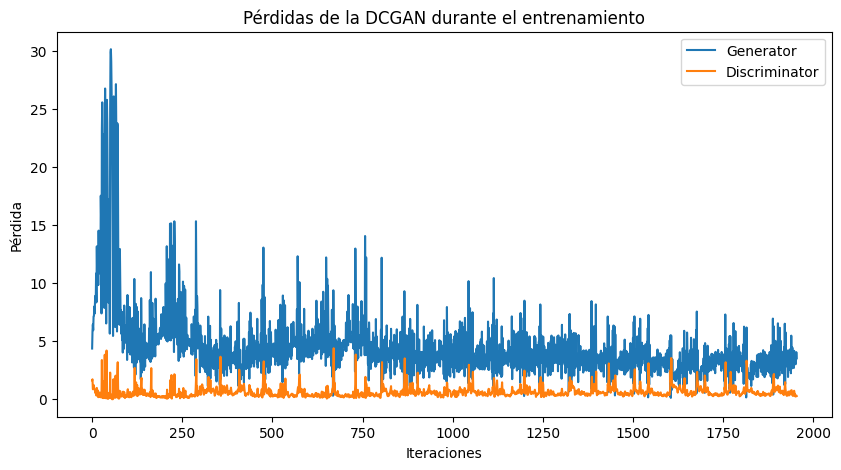

In [15]:
# Gráfica de pérdidas
plt.figure(figsize=(10, 5))
plt.plot(G_losses, label="Generator")
plt.plot(D_losses, label="Discriminator")
plt.legend()
plt.show()


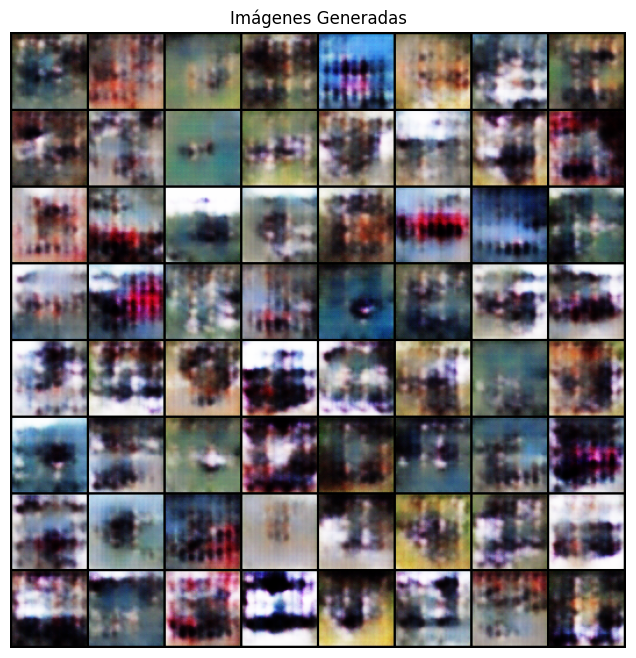

In [18]:
# Resultados de generación
with torch.no_grad():
    fake = netG(fixed_noise)

grid = torchvision.utils.make_grid(
    fake,
    padding=2,
    normalize=True
)

plt.figure(figsize=(4, 8))
plt.imshow(np.transpose(grid, (1, 2, 0)))
plt.axis("off")
plt.show()